> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 0: Welcome & Foundations of Supervised Learning
*The mental model, the workflow, and the toolkit you will use for the rest of the course*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~75 min | 🟢 Beginner | Python basics, NumPy & Pandas (Phases 1–3) |

---
## 🎬 The Hook
Picture a mama mboga at a Nairobi market. After years of selling tomatoes she can *just tell* what tomorrow's price will be: it rained heavily last month, fuel went up, it's end of the month. Nobody ever handed her a formula. She learned from **thousands of examples** where the answer (the price) was eventually revealed.

**That is supervised learning**: show a computer many examples *with answers*, and let it discover the pattern, so it can answer correctly for examples it has never seen.

In the next two weeks you will meet the 13 most important algorithms that do exactly that. But first, we need a shared language and a safety net. Let's build them.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Explain supervised learning, features, targets, regression and classification in plain English.
2. Follow the 7-step supervised learning workflow.
3. Use the scikit-learn `fit` / `predict` / `score` pattern with confidence.
4. Split data properly and explain *why* we never grade a model on the data it studied.
5. Compute MAE, MSE, RMSE and R² by hand and with scikit-learn.
6. Diagnose underfitting vs overfitting using the bias–variance idea.
7. Use cross-validation and baselines to judge whether a model is actually good.

## 🗺️ Roadmap

- What is supervised learning?
- The 7-step workflow
- The scikit-learn API
- Train / test split (the exam analogy)
- Metrics: how wrong are we?
- Baselines
- Bias–variance: underfitting vs overfitting
- Cross-validation
- Pipelines (preview)
- Map of the 13 algorithms
- Worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")

Setup complete ✅


---
## 🧠 1. What is supervised learning?

In supervised learning every training example is a pair **(x, y)**:

- **x**: the *features* (inputs): things we know when we need to predict.
- **y**: the *target* (label, output): the thing we want to predict.

The algorithm learns a function **f** such that **f(x) ≈ y**, and (crucially) it should work on *new* x.

| Task | Target type | Examples | Where in this course |
|---|---|---|---|
| Regression | A **number** (continuous) | House price, student score, tomorrow's maize price | Phase 4a (Lessons 01–08) |
| Classification | A **category** (discrete) | Loan approved / rejected, spam / not spam, flower species | Phase 4b (Lessons 09–16) |

Let's look at a real (small) dataset. **Advertising**: how much a company spent on TV, radio and newspaper ads (in thousands) and how many thousand units it then sold.

In [2]:
ads = pd.read_csv(data_path("advertising.csv"))
print("Shape:", ads.shape, " -> 200 examples, 4 columns")
ads.head()

Shape: (200, 4)  -> 200 examples, 4 columns


,tv_budget_k,radio_budget_k,newspaper_budget_k,sales_k_units
0,233.3,34.0,64.3,19.13
1,134.5,19.5,41.7,14.05
2,258.3,24.9,52.0,19.75
3,210.7,22.7,27.8,13.96
4,32.8,29.7,43.5,10.95


Here the **features** are the three budgets and the **target** is `sales_k_units`. Because the target is a number, this is a **regression** problem.

> 🤔 **Pause and think.**
>
> Suppose a bank wants to predict whether a customer will default on a loan. Is that regression or classification? What would the target look like? *(Answer at the bottom of the notebook.)*

---
## 🧭 2. The 7-step workflow

Every project in this course, and most in your career, follows the same rhythm. Memorise it:

```
 1. FRAME      →  What exactly are we predicting? How will we measure success?
 2. EXPLORE    →  Look at the data: distributions, missing values, weird rows.
 3. PREPARE    →  Clean, encode categories, scale numbers (inside a Pipeline!).
 4. SPLIT      →  Lock away a test set. Do NOT touch it until the very end.
 5. TRAIN      →  Fit one or more models on the training set.
 6. EVALUATE   →  Compare using validation / cross-validation. Tune hyper-parameters.
 7. DELIVER    →  One final test-set score, error analysis, and a clear explanation.
```

> 🔑 **Key idea.**
>
> Most beginners spend 90 % of their energy on step 5 (the fancy algorithm). Professionals spend it on steps 1–4 and 6. A mediocre algorithm on well-prepared data beats a brilliant algorithm on messy data almost every time.

---
## 🔧 3. The scikit-learn API: one pattern to rule them all

Scikit-learn's genius is **consistency**. Every model, from linear regression to SVMs, speaks the same three verbs:

| Verb | What it does |
|---|---|
| `model.fit(X, y)` | **Learn** from the training data |
| `model.predict(X_new)` | **Predict** targets for new rows |
| `model.score(X, y)` | **Grade** itself (R² for regression, accuracy for classification) |

Conventions: `X` is **2-D** (rows × features): even when you have one feature, and `y` is **1-D**.

In [3]:
from sklearn.linear_model import LinearRegression

X = ads[["tv_budget_k"]]          # 2-D: a DataFrame with ONE column (double brackets!)
y = ads["sales_k_units"]          # 1-D: a Series

model = LinearRegression()        # 1. choose the algorithm
model.fit(X, y)                   # 2. learn from examples
new_ad = pd.DataFrame({"tv_budget_k": [100, 200]})
print("Predicted sales for TV budgets 100k and 200k:", model.predict(new_ad).round(2))
print("R² on the data it learned from:", round(model.score(X, y), 3))

Predicted sales for TV budgets 100k and 200k: [11.88 17.  ]
R² on the data it learned from: 0.686


> 🪤 **Common trap.**
>
> `X = ads['tv_budget_k']` (single brackets) gives a 1-D Series and scikit-learn will complain: *"Expected 2D array, got 1D array instead"*. Use **double brackets** `ads[['tv_budget_k']]`.

---
## 📝 4. Train / test split: the exam analogy

Imagine a teacher who gives students the **exact exam questions** to study from, then grades them on those same questions. Everyone gets 100 %, but did anyone learn? Of course not: they may have just *memorised*.

Machine learning has the same danger. So we **hide** part of the data (the **test set**), train on the rest (the **training set**), and grade on the hidden part. The test score estimates how the model will behave on *tomorrow's* real data.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

X = ads[["tv_budget_k", "radio_budget_k", "newspaper_budget_k"]]
y = ads["sales_k_units"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train:", X_train.shape, " test:", X_test.shape)

# A model that is *allowed* to memorise: an unlimited-depth decision tree
memoriser = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"R² on TRAIN data: {memoriser.score(X_train, y_train):.3f}   <- looks perfect!")
print(f"R² on TEST  data: {memoriser.score(X_test,  y_test ):.3f}   <- the honest number")

train: (160, 3)  test: (40, 3)
R² on TRAIN data: 1.000   <- looks perfect!
R² on TEST  data: 0.752   <- the honest number


See the gap? A perfect training score paired with a much worse test score is the classic fingerprint of **overfitting** (we will explore it properly in section 7).

> 💡 **Pro tip.**
>
> `random_state=42` makes the shuffle reproducible, so your results match your classmates' and your own from yesterday. Typical splits: 80/20 or 70/30. With *tiny* datasets prefer cross-validation (section 8).

---
## 📏 5. Metrics for regression: how wrong are we?

For each example, the **error** (residual) is $e_i = y_i - \hat{y}_i$ (true minus predicted). We need one number that summarises all errors. The popular choices:

| Metric | Formula | Units | Personality |
|---|---|---|---|
| **MAE**: Mean Absolute Error | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | same as y | "On average I'm off by this much." Robust to outliers. |
| **MSE**: Mean Squared Error | $\frac{1}{n}\sum (y_i-\hat y_i)^2$ | y² | Punishes big mistakes heavily. Smooth → easy to optimise. |
| **RMSE**: Root MSE | $\sqrt{\text{MSE}}$ | same as y | MSE translated back to y's units. The most common report. |
| **R²**: Coefficient of determination | $1-\dfrac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | none | "Fraction of variance explained." 1 = perfect, 0 = no better than predicting the mean, **can be negative**. |

> 📐 **Math note.**
>
> R² compares your model to the laziest possible model: *always predict the mean $\bar y$*. The numerator is **your** squared error (SSE); the denominator is the lazy model's squared error (SST). If you do as badly as the lazy model, SSE/SST = 1 and R² = 0.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true = np.array([200., 250., 300., 410.])
y_pred = np.array([210., 240., 330., 380.])

errors = y_true - y_pred
mae  = np.mean(np.abs(errors))
mse  = np.mean(errors ** 2)
rmse = np.sqrt(mse)
sse  = np.sum(errors ** 2)
sst  = np.sum((y_true - y_true.mean()) ** 2)
r2   = 1 - sse / sst

print(f"errors : {errors}")
print(f"MAE={mae:.2f}  MSE={mse:.2f}  RMSE={rmse:.2f}  R²={r2:.4f}")
print("--- scikit-learn agrees? ---")
print(f"MAE={mean_absolute_error(y_true, y_pred):.2f}  MSE={mean_squared_error(y_true, y_pred):.2f}  "
      f"RMSE={np.sqrt(mean_squared_error(y_true, y_pred)):.2f}  R²={r2_score(y_true, y_pred):.4f}")

errors : [-10.  10. -30.  30.]
MAE=20.00  MSE=500.00  RMSE=22.36  R²=0.9174
--- scikit-learn agrees? ---
MAE=20.00  MSE=500.00  RMSE=22.36  R²=0.9174


> 💡 **Pro tip.**
>
> **Which metric should I report?** Use **RMSE or MAE** to tell stakeholders *how many shillings / marks / units* you're off by. Use **R²** to compare models on the same data. If a few huge errors would be catastrophic, favour RMSE; if you want a typical-error figure that outliers don't distort, favour MAE.

---
## 🪜 6. Baselines: the bar every model must clear

Before celebrating an R² of 0.7, ask: *compared to what?* A **baseline** is the dumbest sensible model. For regression, that's "always predict the training mean". If your fancy model can't beat it, something is wrong.

In [6]:
from sklearn.dummy import DummyRegressor

base = DummyRegressor(strategy="mean").fit(X_train, y_train)
lin  = LinearRegression().fit(X_train, y_train)
for name, m in [("Baseline (mean)", base), ("Linear regression", lin)]:
    pred = m.predict(X_test)
    print(f"{name:<20} RMSE={np.sqrt(mean_squared_error(y_test, pred)):.3f}   R²={r2_score(y_test, pred):.3f}")

Baseline (mean)      RMSE=5.080   R²=-0.051
Linear regression    RMSE=1.588   R²=0.897


The baseline's R² is ≈ 0 on the test set (by definition, it explains none of the variance). Linear regression slashes the error: *now* we can say it learned something real.

---
## ⚖️ 7. Underfitting, overfitting and the bias–variance trade-off

Let's run the most important experiment in machine learning. We create data from a known curve, $y = \sin(2\pi x) + \text{noise}$, and fit polynomials of increasing flexibility (degree 1 = a straight line, degree 14 = a wiggly monster).

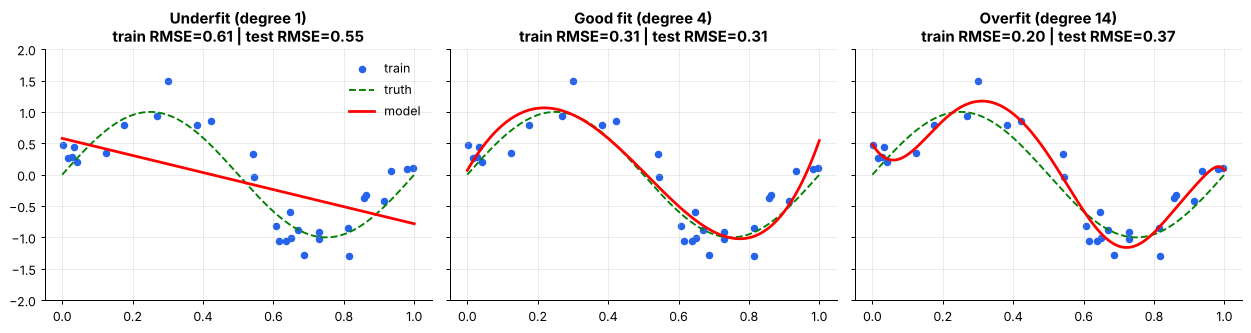

In [7]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(0)
true_f = lambda x: np.sin(2 * np.pi * x)
x_tr = rng.uniform(0, 1, 30);   y_tr = true_f(x_tr) + rng.normal(0, 0.3, 30)     # small training set
x_te = rng.uniform(0, 1, 500);  y_te = true_f(x_te) + rng.normal(0, 0.3, 500)    # big fresh test set

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
xs = np.linspace(0, 1, 300)
for ax, (deg, label) in zip(axes, [(1, "Underfit (degree 1)"), (4, "Good fit (degree 4)"), (14, "Overfit (degree 14)")]):
    m = make_pipeline(PolynomialFeatures(deg), LinearRegression()).fit(x_tr[:, None], y_tr)
    ax.scatter(x_tr, y_tr, s=25, label="train")
    ax.plot(xs, true_f(xs), "g--", lw=1.5, label="truth")
    ax.plot(xs, m.predict(xs[:, None]), "r", lw=2.2, label="model")
    ax.set_ylim(-2, 2)
    tr = np.sqrt(mean_squared_error(y_tr, m.predict(x_tr[:, None])))
    te = np.sqrt(mean_squared_error(y_te, m.predict(x_te[:, None])))
    ax.set_title(f"{label}\ntrain RMSE={tr:.2f} | test RMSE={te:.2f}")
axes[0].legend(); plt.tight_layout(); plt.show()

- **Degree 1: underfitting (high bias):** too simple to capture the curve. Bad on train *and* test.
- **Degree 4: just right:** captures the trend, ignores the noise.
- **Degree 14: overfitting (high variance):** threads through every training dot (tiny train error) but swings wildly between them: terrible on new data.

Let's sweep *every* degree and draw the famous U-shaped curve.

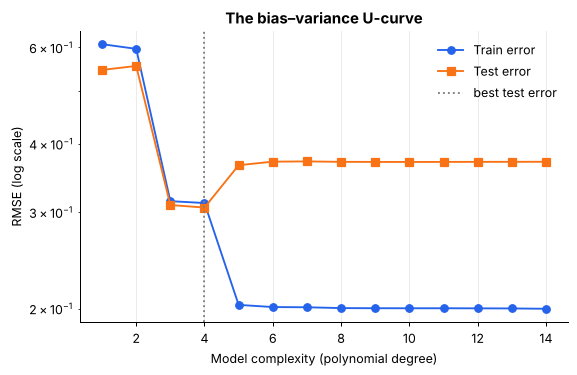

Best degree on the test set: 4


In [8]:
degrees = range(1, 15)
train_err, test_err = [], []
for d in degrees:
    m = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(x_tr[:, None], y_tr)
    train_err.append(np.sqrt(mean_squared_error(y_tr, m.predict(x_tr[:, None]))))
    test_err.append(np.sqrt(mean_squared_error(y_te, m.predict(x_te[:, None]))))

plt.plot(degrees, train_err, "o-", label="Train error")
plt.plot(degrees, test_err, "s-", label="Test error")
plt.yscale("log"); plt.xlabel("Model complexity (polynomial degree)"); plt.ylabel("RMSE (log scale)")
plt.axvline(int(np.argmin(test_err)) + 1, color="gray", ls=":", label="best test error")
plt.title("The bias–variance U-curve"); plt.legend(); plt.show()
print("Best degree on the test set:", int(np.argmin(test_err)) + 1)

> 🔑 **Key idea.**
>
> Training error **always** keeps falling as the model gets more flexible. Test error falls, bottoms out, then **rises**.
>
> - **Bias** = error from wrong assumptions (model too simple) → *underfitting*.
> - **Variance** = error from being too sensitive to the particular training sample (model too flexible) → *overfitting*.
>
> Every algorithm in this course has a "complexity dial" (tree depth, *k* in KNN, *C* in SVM...). Your job is to find the sweet spot.

**A quick diagnostic table**: memorise it, you will use it constantly:

| Train error | Test error | Diagnosis | Typical cure |
|---|---|---|---|
| Low | Low | ✅ Good fit | Ship it (after checking the test set once) |
| High | High | 🥶 Underfitting | More flexible model, better features, less regularisation |
| Low | High (big gap) | 🔥 Overfitting | More data, simpler model, regularisation, pruning, bagging |

---
## 🔁 8. Cross-validation: a fairer exam

One train/test split can be lucky or unlucky. **K-fold cross-validation** repeats the exam K times: split the data into K equal folds, train on K−1 folds, test on the remaining one, rotate, and average the K scores. You get a score **and** an idea of how stable it is (the standard deviation).

```
Fold 1: [TEST ][train][train][train][train]
Fold 2: [train][TEST ][train][train][train]
Fold 3: [train][train][TEST ][train][train]     → average the 5 test scores
Fold 4: [train][train][train][TEST ][train]
Fold 5: [train][train][train][train][TEST ]
```

In [9]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, mdl in [("Baseline", DummyRegressor()), ("Linear Regression", LinearRegression()),
                  ("Unlimited Decision Tree", DecisionTreeRegressor(random_state=0))]:
    scores = cross_val_score(mdl, X, y, cv=cv, scoring="r2")
    print(f"{name:<24} R² per fold: {np.round(scores, 3)}  ->  mean={scores.mean():.3f} ± {scores.std():.3f}")

Baseline                 R² per fold: [-0.051 -0.002 -0.029 -0.028 -0.002]  ->  mean=-0.022 ± 0.019
Linear Regression        R² per fold: [0.897 0.873 0.886 0.899 0.929]  ->  mean=0.897 ± 0.018
Unlimited Decision Tree  R² per fold: [0.803 0.823 0.8   0.792 0.734]  ->  mean=0.791 ± 0.030


> 💡 **Pro tip.**
>
> Use `scoring='neg_root_mean_squared_error'` for RMSE. Scikit-learn *maximises* scores, so error metrics come with a minus sign (multiply by −1 to read them).

---
## 🚰 9. Pipelines (a preview you will use everywhere)

Real data needs preprocessing (scaling, encoding, imputing). The classic mistake: compute the scaling statistics on the **whole** dataset, then split. The test set has now quietly influenced training: this is **data leakage**. A `Pipeline` bundles preprocessing + model so everything is re-learned *inside* each training fold.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

pipe = Pipeline([
    ("scale", StandardScaler()),                 # learned on the training part only
    ("knn",   KNeighborsRegressor(n_neighbors=7)),
])
scores = cross_val_score(pipe, X, y, cv=cv, scoring="r2")
print(f"KNN with scaling inside a Pipeline: R² = {scores.mean():.3f} ± {scores.std():.3f}")

KNN with scaling inside a Pipeline: R² = 0.867 ± 0.038


---
## 🗺️ 10. The map of the 13 algorithms you will master

Think of each algorithm as a personality. By the end of the course you'll know which one to hire for which job.

| Lesson | Algorithm | Task | One-line personality |
|---|---|---|---|
| 01 | Simple Linear Regression | Regression | The straight-line thinker: one feature, one slope. |
| 02 | Multiple Linear Regression | Regression | Straight lines in many dimensions; very interpretable. |
| 03 | Polynomial Regression | Regression | A linear model wearing curved glasses. |
| 04 | Decision Tree (Regression) | Regression | 20 questions → average of the leaf. |
| 05 | Random Forest (Regression) | Regression | A committee of decorrelated trees. |
| 06 | Support Vector Regression | Regression | Fit within a tube; only the outliers of the tube matter. |
| 07 | KNN (Regression) | Regression | Ask your k nearest neighbours and average. |
| 10 | Logistic Regression | Classification | Squash a linear score into a probability. |
| 11 | Decision Tree (Classification) | Classification | 20 questions → majority class of the leaf. |
| 12 | Random Forest (Classification) | Classification | A committee vote. |
| 13 | KNN (Classification) | Classification | You are the company you keep. |
| 14 | Naive Bayes | Classification | Bayes' theorem + a bold independence assumption. |
| 15 | Support Vector Machine | Classification | Find the widest street between classes. |

---
## 🧪 11. Worked examples

### Worked Example A: Computing metrics by hand

**Question.** A model predicts house prices (in millions): predictions $\hat y = [12, 18, 25]$ for true prices $y = [10, 20, 30]$.
Compute MAE, RMSE and R².

**Solution.**

1. Errors $y-\hat y = [-2, 2, 5]$.
2. MAE $= (2+2+5)/3 = 3.0$.
3. MSE $= (4+4+25)/3 = 11$ → RMSE $=\sqrt{11}\approx 3.317$.
4. $\bar y = 20$; SST $= (10-20)^2+(20-20)^2+(30-20)^2 = 200$; SSE $= 4+4+25 = 33$.
5. R² $= 1 - 33/200 = \mathbf{0.835}$.

Let's verify in code:

In [11]:
y_a = np.array([10, 20, 30]); yh_a = np.array([12, 18, 25])
print("MAE :", mean_absolute_error(y_a, yh_a))
print("RMSE:", round(float(np.sqrt(mean_squared_error(y_a, yh_a))), 3))
print("R²  :", round(r2_score(y_a, yh_a), 3))

MAE : 3.0
RMSE: 3.317
R²  : 0.835


### Worked Example B: Diagnosing a model from its scores

| Model | Train R² | Test R² |
|---|---|---|
| A | 0.42 | 0.40 |
| B | 0.99 | 0.55 |
| C | 0.86 | 0.84 |

- **A**: both low, no gap → **underfitting** (high bias). Needs a more flexible model or better features.
- **B**: huge gap → **overfitting** (high variance). Simplify, regularise, or get more data.
- **C**: both high, tiny gap → **good fit**. 

This reasoning is how you'll debug *every* model in the course.

---
### 🧩 Problem 1: Metrics by hand  ⭐

A model predicts `y_pred = [2.5, 5, 4, 8]` for the true values `y_true = [3, 5, 2.5, 7]`.

Compute **MAE**, **RMSE** and **R²** using only NumPy (no scikit-learn metrics). Store them in `mae`, `rmse`, `r2`.

In [12]:
# ✅ SOLUTION
y_true = np.array([3, 5, 2.5, 7]); y_pred = np.array([2.5, 5, 4, 8])
errors = y_true - y_pred
mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))
sse = np.sum(errors ** 2); sst = np.sum((y_true - y_true.mean()) ** 2)
r2 = 1 - sse / sst
print(mae, rmse, r2)

0.75 0.9354143466934853 0.7241379310344828


**Why this works.** SSE = 3.5 and SST = 12.6875, so R² = 1 − 3.5/12.6875 ≈ 0.724. MAE averages |errors| = (0.5+0+1.5+1)/4 = 0.75.

In [13]:
check("MAE = 0.75", lambda: abs(mae - 0.75) < 1e-9)
check("RMSE ≈ 0.9354", lambda: abs(rmse - 0.935414) < 1e-4)
check("R² ≈ 0.7241", lambda: abs(r2 - 0.724138) < 1e-4)

✅  MAE = 0.75
✅  RMSE ≈ 0.9354
✅  R² ≈ 0.7241


---
### 🧩 Problem 2: Split the advertising data  ⭐

Split `X` (the three budget columns) and `y` (sales) from the `ads` DataFrame into **80 % train / 20 % test** using `random_state=42`. Name the pieces `Xtr, Xte, ytr, yte`.

In [14]:
# ✅ SOLUTION
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

**Why this works.** `random_state=42` guarantees the same shuffle as the lesson's `X_train`, which is why the last check passes.

In [15]:
check("train has 160 rows", lambda: len(Xtr) == 160 and len(ytr) == 160)
check("test has 40 rows",  lambda: len(Xte) == 40 and len(yte) == 40)
check("same split as the lesson", lambda: list(Xtr.index[:3]) == list(X_train.index[:3]))

✅  train has 160 rows
✅  test has 40 rows
✅  same split as the lesson


---
### 🧩 Problem 3: Beat the baseline  ⭐

Using the lesson's `X_train, X_test, y_train, y_test`:

1. Fit a `DummyRegressor(strategy='mean')` and a `LinearRegression()`.
2. Store their **test-set RMSE** in `rmse_base` and `rmse_lin`.
3. Set `improvement` = the percentage by which linear regression reduces the baseline RMSE.

In [16]:
# ✅ SOLUTION
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
lin2 = LinearRegression().fit(X_train, y_train)
rmse_base = np.sqrt(mean_squared_error(y_test, dummy.predict(X_test)))
rmse_lin = np.sqrt(mean_squared_error(y_test, lin2.predict(X_test)))
improvement = (rmse_base - rmse_lin) / rmse_base * 100
print(f"Linear regression cuts error by {improvement:.1f}%")

Linear regression cuts error by 68.7%


**Why this works.** TV and radio spend are strongly predictive of sales, so the linear model removes most of the unexplained variation.

In [17]:
check("linear regression beats the baseline", lambda: rmse_lin < rmse_base)
check("improvement is > 50%", lambda: improvement > 50)

✅  linear regression beats the baseline
✅  improvement is > 50%


---
### 🧩 Problem 4: Write your own doctor  ⭐⭐

Write a function `diagnose(train_score, test_score)` that returns one of the strings `'underfitting'`, `'overfitting'` or `'good fit'` using these rules:

- if `train_score < 0.6` → `'underfitting'`
- elif `train_score - test_score > 0.15` → `'overfitting'`
- else → `'good fit'`

In [18]:
# ✅ SOLUTION
def diagnose(train_score, test_score):
    if train_score < 0.6:
        return "underfitting"
    elif train_score - test_score > 0.15:
        return "overfitting"
    return "good fit"

**Why this works.** Real diagnosis is a judgement call, but encoding a rule of thumb makes you think about *which* symptoms matter.

In [19]:
check("model A (0.42 / 0.40) -> underfitting", lambda: diagnose(0.42, 0.40) == "underfitting")
check("model B (0.99 / 0.55) -> overfitting",  lambda: diagnose(0.99, 0.55) == "overfitting")
check("model C (0.86 / 0.84) -> good fit",     lambda: diagnose(0.86, 0.84) == "good fit")

✅  model A (0.42 / 0.40) -> underfitting
✅  model B (0.99 / 0.55) -> overfitting
✅  model C (0.86 / 0.84) -> good fit


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** Predicting whether a customer will default on a loan: regression or classification?

<details><summary>👀 Show answer</summary>

**Classification**: the target is a category (default / no default).

</details>

**Q2.** Your model has train R² = 0.97 and test R² = 0.61. What's wrong, and name two cures?

<details><summary>👀 Show answer</summary>

**Overfitting.** Cures: collect more data, simplify the model (smaller depth / fewer polynomial terms), add regularisation, use bagging/ensembles, prune.

</details>

**Q3.** Why must the test set stay untouched until the very end?

<details><summary>👀 Show answer</summary>

If we tune the model by peeking at the test set, it stops being an honest estimate of future performance: it becomes part of training.

</details>

**Q4.** Can R² be negative? What does that mean?

<details><summary>👀 Show answer</summary>

Yes. It means the model is **worse than just predicting the mean**: usually a sign of severe overfitting or a bug.

</details>

**Q5.** What is data leakage, and how do Pipelines help?

<details><summary>👀 Show answer</summary>

Leakage = information from outside the training fold (e.g. test statistics) influencing training. A Pipeline fits the preprocessing steps only on each training fold.

</details>

---
## 🔁 Recap

- Supervised learning = learning f(x) ≈ y from labelled examples; **regression** → number, **classification** → category.
- Follow the 7-step workflow; the algorithm is only step 5.
- `fit` → `predict` → `score` is the universal scikit-learn pattern.
- Always evaluate on data the model hasn't seen; always compare against a baseline.
- Underfitting = too simple, overfitting = too flexible; cross-validation helps you find the middle.

### ➡️ Up next: **Simple Linear Regression**
Open `01_Simple_Linear_Regression.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀